# Biblioteca escolar: exploração dos empréstimos

Neste notebook explorei o arquivo `biblioteca_escolar.csv`, com 20 empréstimos feitos em outubro de 2026. Fui por partes: primeiro entender a base, depois ajustar as datas, calcular os dias de empréstimo e de atraso, e por fim contar por turma, livro e gênero.

A pergunta que eu quis responder: **quais livros ainda não voltaram e há quanto tempo estão fora?**

In [3]:
import pandas as pd
import matplotlib.pyplot as plt
from pathlib import Path

## 1. Carregando os dados

O arquivo usa ponto e vírgula como separador, então precisei passar `sep=";"`. Sem isso o Pandas junta tudo numa coluna só.

In [4]:
df = pd.read_csv("dados/biblioteca_escolar.csv", sep=";")

print(df.shape)  # linhas e colunas
df.head()

(20, 7)


,aluno,turma,livro,genero,data_emprestimo,data_devolucao,status
0,Ana Clara,1A,O Pequeno Príncipe,Aventura,2026-10-01,2026-10-08,Devolvido
1,Lucas,1B,Chapeuzinho Vermelho,Conto,2026-10-02,2026-10-09,Devolvido
2,Mariana,2A,A Menina e o Dragão,Fantasia,2026-10-03,2026-10-10,Devolvido
3,Pedro,2B,O Pequeno Príncipe,Aventura,2026-10-04,NaN,Em andamento
4,Beatriz,1A,A Ilha do Tesouro,Aventura,2026-10-05,2026-10-12,Devolvido


## 2. Conhecendo a base

Antes de calcular qualquer coisa, olhei os tipos das colunas, os valores vazios e se existe linha repetida.

In [5]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 20 entries, 0 to 19
Data columns (total 7 columns):
 #   Column           Non-Null Count  Dtype
---  ------           --------------  -----
 0   aluno            20 non-null     str  
 1   turma            20 non-null     str  
 2   livro            20 non-null     str  
 3   genero           20 non-null     str  
 4   data_emprestimo  20 non-null     str  
 5   data_devolucao   13 non-null     str  
 6   status           20 non-null     str  
dtypes: str(7)
memory usage: 2.4 KB


In [6]:
print("Valores vazios por coluna:")
print(df.isna().sum())

print()
print("Linhas duplicadas:", df.duplicated().sum())

Valores vazios por coluna:
aluno              0
turma              0
livro              0
genero             0
data_emprestimo    0
data_devolucao     7
status             0
dtype: int64

Linhas duplicadas: 0


O que vi:

- 20 linhas e 7 colunas.
- Todas as colunas vieram como texto, inclusive as duas de data.
- Só `data_devolucao` tem valor vazio (7 linhas).
- Nenhuma linha repetida.

Os 7 vazios podem ser erro de preenchimento ou podem ter outra explicação. Comparei com a coluna `status`.

In [7]:
df[df["data_devolucao"].isna()]["status"].value_counts()

status
Em andamento    7
Name: count, dtype: int64

Os 7 vazios são exatamente os empréstimos "Em andamento". Ou seja, o livro ainda não voltou e por isso não existe data de devolução. Decidi **não apagar nem preencher** esses valores, porque são justamente os registros que mais interessam.

## 3. Ajustando as datas

Como as datas estão como texto, não dá para subtrair uma da outra. Converti as duas colunas com `pd.to_datetime`.

In [8]:
df["data_emprestimo"] = pd.to_datetime(df["data_emprestimo"])
df["data_devolucao"] = pd.to_datetime(df["data_devolucao"])

df.info()

<class 'pandas.DataFrame'>
RangeIndex: 20 entries, 0 to 19
Data columns (total 7 columns):
 #   Column           Non-Null Count  Dtype         
---  ------           --------------  -----         
 0   aluno            20 non-null     str           
 1   turma            20 non-null     str           
 2   livro            20 non-null     str           
 3   genero           20 non-null     str           
 4   data_emprestimo  20 non-null     datetime64[us]
 5   data_devolucao   13 non-null     datetime64[us]
 6   status           20 non-null     str           
dtypes: datetime64[us](2), str(5)
memory usage: 2.1 KB


Agora as duas são `datetime64`. Os vazios viraram `NaT`, que é o equivalente de `NaN` para datas.

## 4. Quanto tempo cada livro ficou emprestado

Criei `dias_emprestado`, que é a data de devolução menos a data de empréstimo. Só tem valor para quem já devolveu.

In [9]:
df["dias_emprestado"] = (df["data_devolucao"] - df["data_emprestimo"]).dt.days

df["dias_emprestado"].describe()

count    13.0
mean      7.0
std       0.0
min       7.0
25%       7.0
50%       7.0
75%       7.0
max       7.0
Name: dias_emprestado, dtype: float64

Todos os 13 devolvidos ficaram exatamente 7 dias (média 7, desvio 0). Isso é regular demais para uma biblioteca de verdade, onde sempre tem gente que devolve antes ou depois. Vou tratar o dado como uma base de exemplo e lembrar disso nas conclusões.

## 5. Livros pendentes e atraso

Para saber há quantos dias cada livro pendente está fora, preciso de uma data de referência. Em vez de usar a data de hoje (que mudaria a cada vez que eu rodasse o notebook), fixei **01/11/2026**.

Também guardei o prazo em uma variável. O prazo de 7 dias **é uma suposição minha**, tirada do comportamento dos devolvidos. Ele não aparece em nenhum lugar do arquivo.

In [10]:
data_ref = pd.Timestamp("2026-11-01")
prazo = 7

pendentes = df[df["status"] == "Em andamento"].copy()
pendentes["dias_fora"] = (data_ref - pendentes["data_emprestimo"]).dt.days
pendentes["dias_atraso"] = pendentes["dias_fora"] - prazo

pendentes[["aluno", "turma", "livro", "data_emprestimo", "dias_fora", "dias_atraso"]].sort_values("dias_atraso", ascending=False)

,aluno,turma,livro,data_emprestimo,dias_fora,dias_atraso
3,Pedro,2B,O Pequeno Príncipe,2026-10-04,28,21
5,Gabriel,3A,A Menina e o Dragão,2026-10-06,26,19
8,Helena,1B,O Sítio das Descobertas,2026-10-09,23,16
11,Davi,1A,O Sítio das Descobertas,2026-10-12,20,13
14,Alice,1B,Viagem ao Espaço,2026-10-15,17,10
17,Bernardo,1A,A Ilha do Tesouro,2026-10-18,14,7
19,Theo,3B,O Pequeno Príncipe,2026-10-20,12,5


Se o prazo for mesmo de 7 dias, os 7 pendentes estão atrasados, de 5 a 21 dias. O pior caso é o do Pedro (2B), com "O Pequeno Príncipe", que saiu em 04/10.

## 6. Contagens por livro, gênero e turma

In [11]:
print(df["livro"].value_counts())
print()
print(df["genero"].value_counts())
print()
print(df["turma"].value_counts())

livro
O Pequeno Príncipe         4
Viagem ao Espaço           4
Chapeuzinho Vermelho       3
A Menina e o Dragão        3
A Ilha do Tesouro          3
O Sítio das Descobertas    3
Name: count, dtype: int64

genero
Aventura    10
Ficção       4
Conto        3
Fantasia     3
Name: count, dtype: int64

turma
1A    4
2A    4
1B    3
2B    3
3A    3
3B    3
Name: count, dtype: int64


In [12]:
# gênero x status
df.groupby(["genero", "status"]).size().unstack(fill_value=0)

status,Devolvido,Em andamento
genero,,
Aventura,5,5
Conto,3,0
Fantasia,2,1
Ficção,3,1


Aventura aparece em 10 dos 20 empréstimos e em 5 dos 7 pendentes. Chama atenção, mas com 20 linhas uma diferença de um ou dois empréstimos não prova tendência nenhuma. Anotei como ponto de atenção, não como conclusão.

## 7. Gráficos

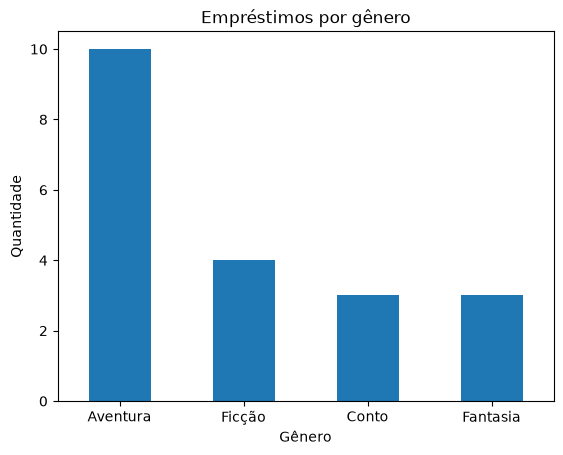

In [13]:
Path("graficos").mkdir(exist_ok=True)

df["genero"].value_counts().plot(kind="bar")
plt.title("Empréstimos por gênero")
plt.xlabel("Gênero")
plt.ylabel("Quantidade")
plt.xticks(rotation=0)
plt.savefig("graficos/grafico_genero.png")
plt.show()

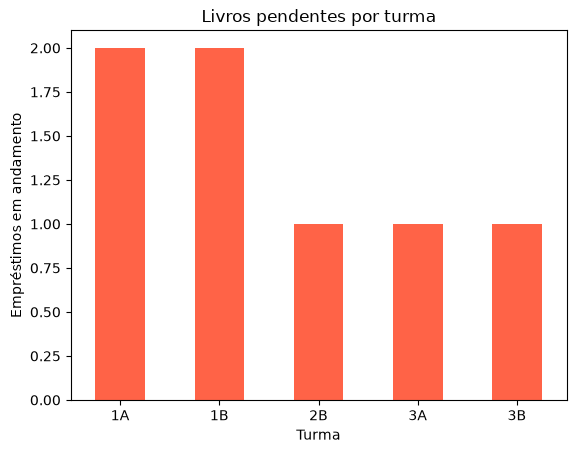

In [14]:
pendentes_turma = df[df["status"] == "Em andamento"].groupby("turma").size()

pendentes_turma.plot(kind="bar", color="tomato")
plt.title("Livros pendentes por turma")
plt.xlabel("Turma")
plt.ylabel("Empréstimos em andamento")
plt.xticks(rotation=0)
plt.savefig("graficos/grafico_pendentes_turma.png")
plt.show()

A turma 2A não aparece no segundo gráfico porque não tem nenhum pendente. As turmas 1A e 1B têm 2 cada.

## 8. Resumo por turma

Montei uma tabela com uma linha por turma, mostrando quantos devolveram, quantos estão com o livro e os nomes dos alunos de cada grupo.

In [15]:
resumo = (
    df.groupby(["turma", "status"])
      .agg(qtd=("aluno", "size"), alunos=("aluno", lambda x: ", ".join(x)))
      .unstack("status")
)

resumo.columns = [f"{a}_{b}" for a, b in resumo.columns]
resumo = resumo.reset_index()

resumo = resumo.rename(columns={
    "qtd_Devolvido": "qtd_devolvidos",
    "qtd_Em andamento": "qtd_em_andamento",
    "alunos_Devolvido": "alunos_devolvidos",
    "alunos_Em andamento": "alunos_em_andamento",
})

# turma sem pendência fica com 0 e "-" em vez de vazio
resumo[["qtd_devolvidos", "qtd_em_andamento"]] = resumo[["qtd_devolvidos", "qtd_em_andamento"]].fillna(0).astype(int)
resumo[["alunos_devolvidos", "alunos_em_andamento"]] = resumo[["alunos_devolvidos", "alunos_em_andamento"]].fillna("-")

resumo = resumo[["turma", "qtd_devolvidos", "alunos_devolvidos", "qtd_em_andamento", "alunos_em_andamento"]]
resumo

,turma,qtd_devolvidos,alunos_devolvidos,qtd_em_andamento,alunos_em_andamento
0,1A,2,"Ana Clara, Beatriz",2,"Davi, Bernardo"
1,1B,1,Lucas,2,"Helena, Alice"
2,2A,4,"Mariana, Sofia, Valentina, Manuela",0,-
3,2B,2,"Arthur, Rafael",1,Pedro
4,3A,2,"Laura, Isabella",1,Gabriel
5,3B,2,"Miguel, Enzo",1,Theo


## 9. Salvando os resultados

Antes de salvar, mudei uma coisa. Eu tinha criado `dias_fora` e `dias_total` para ver os dias dos pendentes, mas as duas misturavam situações diferentes: para quem já devolveu, "dias fora até hoje" não significa nada. Troquei por uma coluna só, `dias_pendente`, preenchida apenas para quem ainda está com o livro. Assim cada linha tem `dias_emprestado` **ou** `dias_pendente`, nunca os dois.

Também converti as duas colunas para `Int64`, que aceita vazio sem transformar o 7 em 7.0.

In [16]:
df["dias_pendente"] = (
    (data_ref - df["data_emprestimo"])
    .dt.days
    .where(df["status"] == "Em andamento")
)

df["dias_emprestado"] = df["dias_emprestado"].astype("Int64")
df["dias_pendente"] = df["dias_pendente"].astype("Int64")

df.columns.tolist()

['aluno',
 'turma',
 'livro',
 'genero',
 'data_emprestimo',
 'data_devolucao',
 'status',
 'dias_emprestado',
 'dias_pendente']

In [17]:
pasta_saida = Path("dados")

df.to_csv(pasta_saida / "biblioteca_escolar_modificado.csv", sep=";", index=False, encoding="utf-8-sig")
resumo.to_csv(pasta_saida / "resumo_por_turma.csv", sep=";", index=False, encoding="utf-8-sig")

print(sorted(p.name for p in pasta_saida.glob("*.csv")))

['biblioteca_escolar.csv', 'biblioteca_escolar_modificado.csv', 'resumo_por_turma.csv']


## O que ficou

- 20 empréstimos: 13 devolvidos e 7 em andamento.
- Todos os devolvidos ficaram 7 dias com o livro.
- Com prazo de 7 dias, os 7 pendentes estão atrasados, de 5 a 21 dias.
- Aventura concentra metade dos empréstimos e 5 dos 7 pendentes.
- 1A e 1B têm 2 pendentes cada, e 2A não tem nenhum.

## Limitações

- O prazo de 7 dias é suposição, não está no arquivo.
- A base é pequena e muito regular, então os números servem para apontar onde olhar, não para concluir causas.
- A data de referência está fixa em 01/11/2026. Para outra data, é só mudar `data_ref`.